# Visual review of raw XML, canonical, YOLO and MOT exports. Review every page, including unannotated samples.


In [1]:
from pathlib import Path
import os
import subprocess
import sys
import json

# Colab mounts Drive; local runs discover the repo from the notebook directory.
try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False

project_override = os.environ.get('UA_DETRAC_PROJECT')
candidates = [Path.cwd(), *Path.cwd().parents]
if project_override:
    candidates.insert(0, Path(project_override))
if IN_COLAB and not project_override:
    candidates.insert(0, Path('/content/drive/MyDrive/CS331/CS331-Vehicle-Tracking'))
ROOT_PATH = next(
    (path for path in candidates if (path / 'scripts/prepare_dataset.py').is_file()),
    None,
)
if ROOT_PATH is None:
    raise FileNotFoundError('Open this notebook from inside the project repository.')

sys.path.insert(0, str(ROOT_PATH))
subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', '-r',
     str(ROOT_PATH / 'requirements.txt')],
    check=True,
)
LOCAL_RAW_PATH = Path(os.environ.get('UA_DETRAC_RAW', ROOT_PATH / 'data/raw'))
if IN_COLAB and 'UA_DETRAC_RAW' not in os.environ:
    downloaded_raw = Path('/content/ua_detrac/raw')
    if downloaded_raw.is_dir():
        LOCAL_RAW_PATH = downloaded_raw
DATA_RAW_PATH = LOCAL_RAW_PATH
WORK_ROOT = Path('/content/ua_detrac') if IN_COLAB else ROOT_PATH / 'outputs/ua_detrac'
WORK_ROOT.mkdir(parents=True, exist_ok=True)
DATASET = Path(os.environ.get('UA_DETRAC_OUTPUT', WORK_ROOT / 'dataset_v1.1'))
INVENTORY_PATH = WORK_ROOT / 'raw_inventory.json'
import pandas as pd
import matplotlib.pyplot as plt

print('Project:', ROOT_PATH)
print('Raw:', DATA_RAW_PATH)
print('Dataset output:', DATASET)

Project: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking
Raw: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking\data\raw
Dataset output: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking\outputs\ua_detrac\dataset_v1.1


In [3]:
import random
from PIL import Image
from matplotlib.patches import Rectangle
from src.data.parse_detrac import parse_detrac
from src.data.utils import write_json

annotations = pd.read_csv(DATASET / 'canonical/annotations.csv')
sequences = pd.read_csv(DATASET / 'metadata/sequences.csv').set_index('sequence')
rng = random.Random(42)
samples = []
for part in ('train', 'val', 'test'):
    manifest = (DATASET / 'detection' / f'{part}.txt').read_text().splitlines()
    samples.extend((part, path) for path in rng.sample(manifest, min(20, len(manifest))))
raw_cache, mot_cache = {}, {}



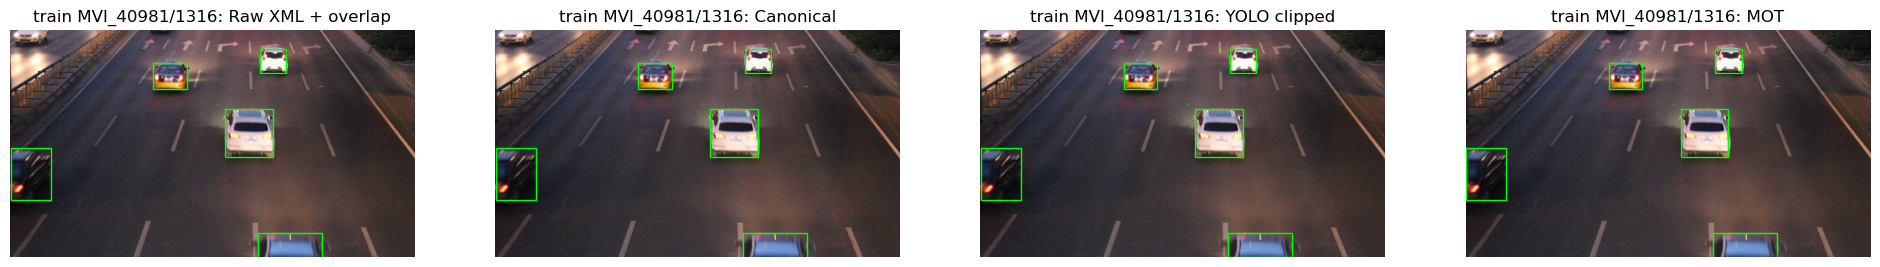

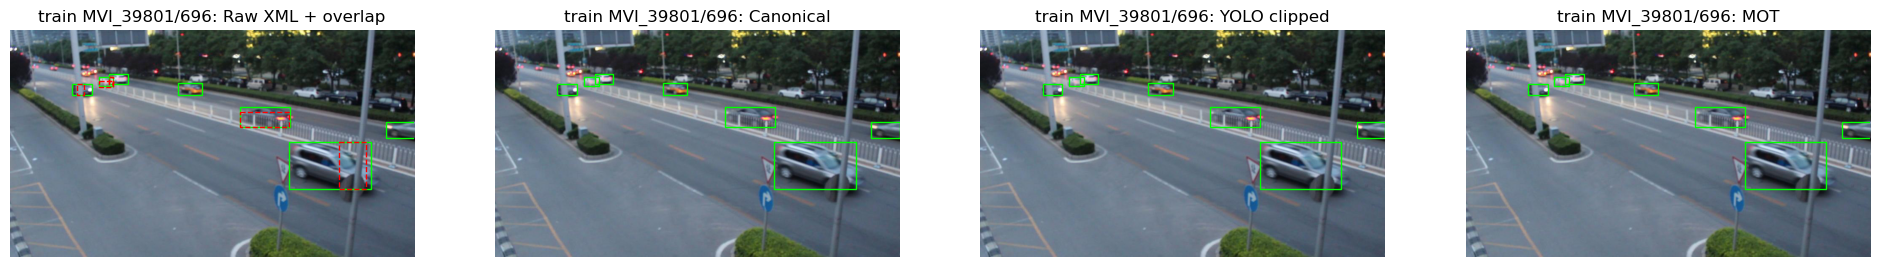

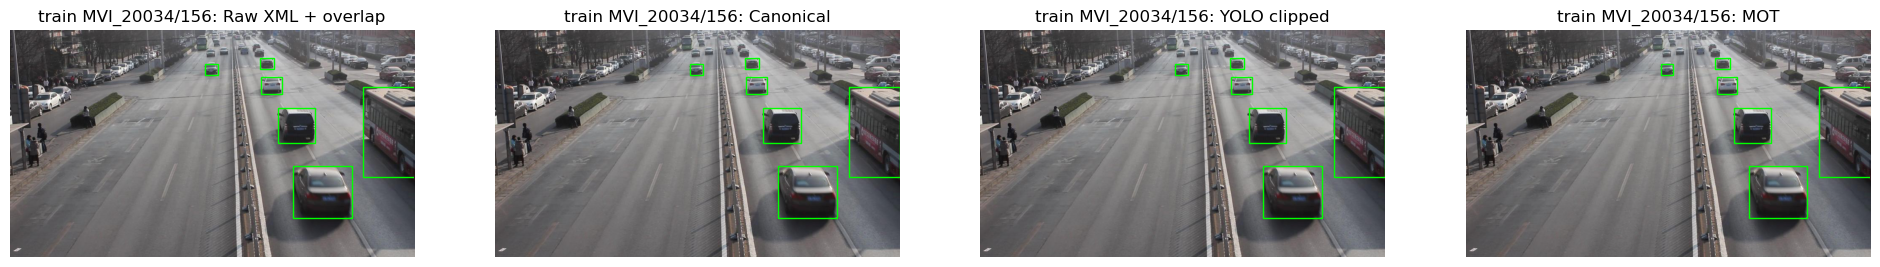

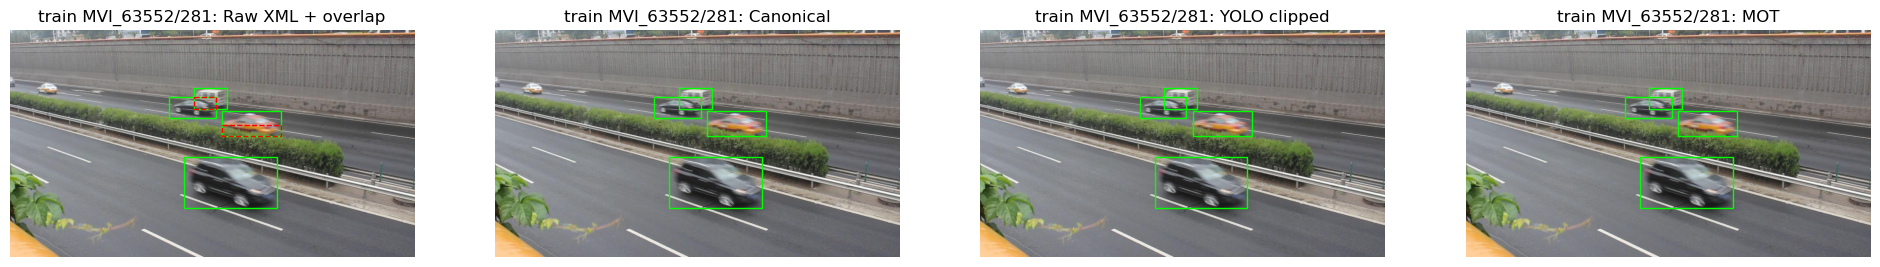

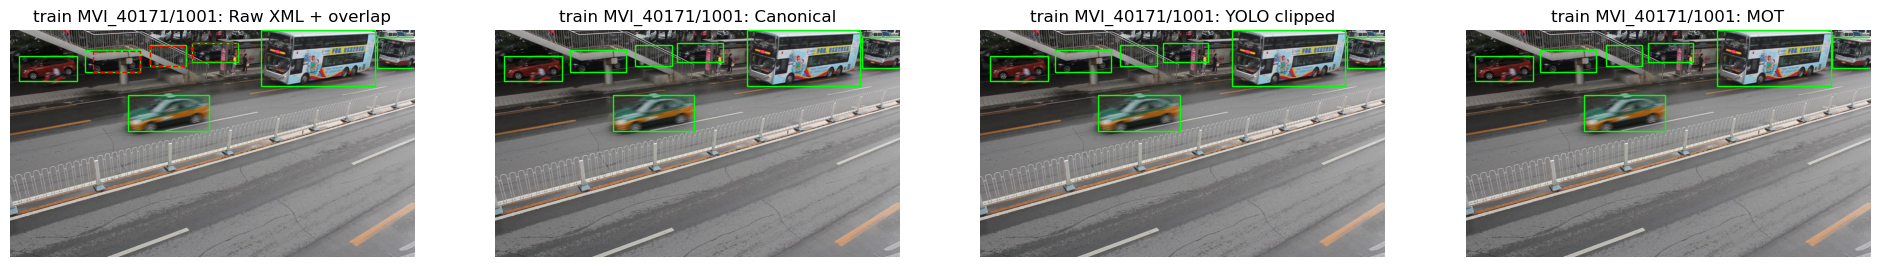

Pages: 12


In [4]:
# Review every page; raw canonical boxes may extend beyond the image edge.
PAGE = 0
PAGE_SIZE = 5
for part, relative in samples[PAGE * PAGE_SIZE:(PAGE + 1) * PAGE_SIZE]:
    image_path = DATASET / 'detection' / relative
    sequence = image_path.parent.name
    frame = int(image_path.stem[3:])
    image = Image.open(image_path)
    width, height = image.size

    if sequence not in raw_cache:
        raw_cache[sequence] = parse_detrac(
            Path(sequences.loc[sequence, 'xml_path']),
            num_frames=int(sequences.loc[sequence, 'num_frames']),
        )[0]
        mot_cache[sequence] = pd.read_csv(
            DATASET / 'tracking' / sequence / 'gt/gt.txt',
            header=None,
            names=['frame_id', 'track_id', 'x', 'y', 'w', 'h',
                   'confidence', 'class_id', 'visibility'],
        )

    figure, axes = plt.subplots(1, 4, figsize=(24, 5))
    tables = [
        raw_cache[sequence],
        annotations[annotations.sequence == sequence],
        None,
        mot_cache[sequence],
    ]
    for axis, title, table in zip(
        axes, ('Raw XML + overlap', 'Canonical', 'YOLO clipped', 'MOT'), tables
    ):
        axis.imshow(image)
        axis.set_title(f'{part} {sequence}/{frame}: {title}')
        axis.axis('off')
        if table is not None:
            for row in table[table.frame_id == frame].itertuples():
                axis.add_patch(Rectangle(
                    (row.x, row.y), row.w, row.h,
                    fill=False, edgecolor='lime',
                ))

    # Red dashed boxes show XML region_overlap entries.
    raw_rows = raw_cache[sequence]
    for row in raw_rows[raw_rows.frame_id == frame].itertuples():
        for region in json.loads(row.occlusion_regions_json):
            axes[0].add_patch(Rectangle(
                (region['left'], region['top']),
                region['width'], region['height'],
                fill=False, edgecolor='red', linestyle='--',
            ))

    label_path = DATASET / 'detection/labels' / sequence / f'{image_path.stem}.txt'
    for line in label_path.read_text().splitlines():
        class_id, center_x, center_y, box_w, box_h = map(float, line.split())
        x = (center_x - box_w / 2) * width
        y = (center_y - box_h / 2) * height
        axes[2].add_patch(Rectangle(
            (x, y), box_w * width, box_h * height,
            fill=False, edgecolor='lime',
        ))
    plt.show()
print('Pages:', (len(samples) + PAGE_SIZE - 1) // PAGE_SIZE)



## Inspect sampled frames without XML annotations


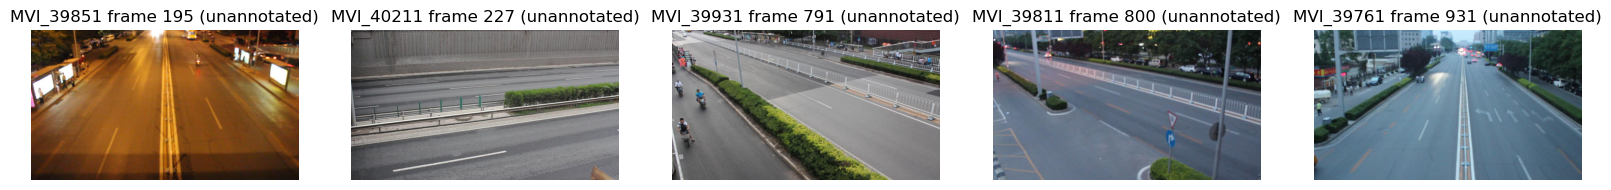

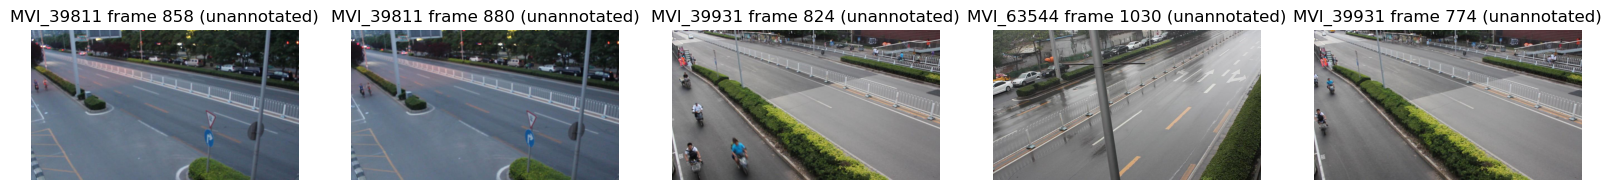

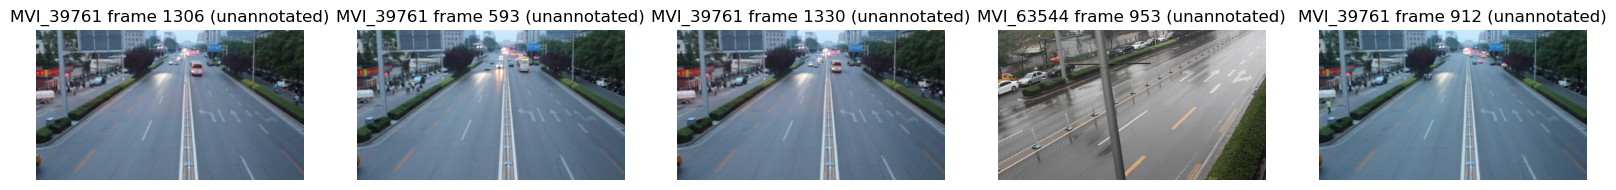

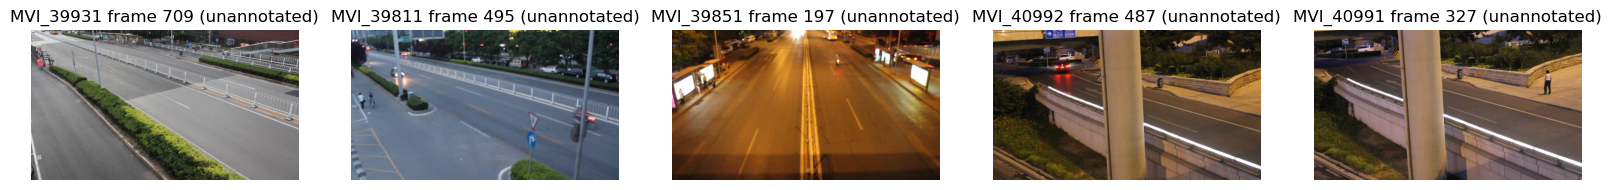

In [ ]:
# Inspect unknown frames separately; do not treat them as negative examples.
unknown = pd.read_csv(DATASET / 'metadata/unannotated_frames.csv')
unknown_samples = unknown.sample(
    min(20, len(unknown)), random_state=42
).to_dict('records')
for start in range(0, len(unknown_samples), 5):
    batch = unknown_samples[start:start + 5]
    figure, axes = plt.subplots(1, len(batch), figsize=(20, 4))
    if len(batch) == 1:
        axes = [axes]
    for axis, row in zip(axes, batch):
        image_path = (
            DATASET / 'tracking' / row['sequence'] / 'img1'
            / f"{int(row['frame_id']):06d}.jpg"
        )
        axis.imshow(Image.open(image_path))
        axis.set_title(f"{row['sequence']} frame {row['frame_id']} (unannotated)")
        axis.axis('off')
    plt.show()

In [7]:
# Set True ONLY after reviewing all pages and confirming correctness.
VISUAL_REVIEW_PASSED = True
if VISUAL_REVIEW_PASSED:
    path = DATASET / 'metadata/manifest.json'
    manifest = json.loads(path.read_text())
    manifest['visual_inspection'] = 'PASSED'
    manifest['visual_review_sample'] = dict(
        seed=42, frames=samples, unannotated_frames=unknown_samples
    )
    write_json(path, manifest)
